<a href="https://colab.research.google.com/github/BenjaminOrtizO/CaseStudy/blob/main/Entrega1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#CASE OF STUDY: BEBIDAS MAIPO S.A.
##Parte 1: Calidad y Pronóstico.
###Cargar el repositorio


In [206]:
!git clone https://github.com/BenjaminOrtizO/CaseStudy.git

# Entrar al repositorio
%cd /content/CaseStudy


!git pull

fatal: destination path 'CaseStudy' already exists and is not an empty directory.
/content/CaseStudy
Already up to date.


#LIBRERÍAS UTILIZADAS

In [207]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

###Cargar los datos (Parte A)


In [208]:
# Datos maestros
maestro_sku = pd.read_csv('Datos/maestro_sku.csv')
inventario_inicial = pd.read_csv('Datos/inventario_inicial.csv')

# Demanda y capacidad
demanda_semanal = pd.read_csv('Datos/demanda_semanal.csv', parse_dates=['fecha_lunes'])
capacidad_horizonte = pd.read_csv('Datos/capacidad_horizonte.csv')
compromisos_semana_focal = pd.read_csv('Datos/compromisos_semana_focal.csv')

# Calidad
calidad_atributos = pd.read_csv('Datos/calidad_atributos.csv' , parse_dates=['fecha'])
calidad_llenado = pd.read_csv('Datos/calidad_llenado.csv', parse_dates=['fecha'])
especificaciones_calidad = pd.read_csv('Datos/especificaciones_calidad.csv')

# Configuración
setups_cip = pd.read_csv('Datos/setups_cip.csv')

# Metadatos
with open('Datos/metadatos.json', 'r', encoding='utf-8') as f:
    metadatos = json.load(f)

metadatos #equivalente a print en Jupyter

{'empresa': 'Bebidas del Maipo S.A.',
 'semilla': 20260923,
 'n_semanas_historia': 156,
 'fin_historia': '2026-09-21',
 'horizonte_planificacion': 13,
 'semana_focal_secuenciamiento': 12,
 'fecha_semana_focal': '2026-12-14',
 'n_sku': 9,
 'familias': ['CIT', 'FUN', 'NEC']}

In [209]:
calidad_llenado.head()

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11


In [210]:
calidad_atributos.head()

,fecha,semana_registro,turno,linea,sku,n_inspeccionadas,n_defectuosas,causa_principal
0,2026-07-20,1,A (06-14),L1,FUN-B05,238,1,Envase deformado
1,2026-07-20,1,B (14-22),L1,CIT-L05,182,3,Etiqueta
2,2026-07-21,1,A (06-14),L1,NEC-D05,190,4,Envase deformado
3,2026-07-21,1,B (14-22),L1,CIT-L05,194,3,Nivel de llenado
4,2026-07-22,1,A (06-14),L1,CIT-L05,190,8,Etiqueta


In [211]:
especificaciones_calidad.head()

,formato_L,nominal_mL,LIE_mL,LSE_mL,tolerancia_oiml_mL,limite_legal_inferior_mL
0,0.5,500.0,492.0,508.0,15.0,485.0
1,1.5,1500.0,1485.0,1515.0,22.5,1477.5
2,3.0,3000.0,2975.0,3025.0,45.0,2955.0


In [212]:
maestro_sku.head()

,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400


In [213]:
demanda_semanal.head()

,semana,fecha_lunes,anio_iso,semana_iso,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
0,1,2023-10-02,2023,40,NEC-D05,1209.0,0.0,0,6620,6620
1,2,2023-10-09,2023,41,NEC-D05,1095.0,0.0,0,6620,6620
2,3,2023-10-16,2023,42,NEC-D05,1345.0,0.0,0,6620,6620
3,4,2023-10-23,2023,43,NEC-D05,1888.0,0.0,1,6620,4819
4,5,2023-10-30,2023,44,NEC-D05,991.0,0.0,0,6620,6620


In [214]:
calidad_llenado['fecha'] = pd.to_datetime(calidad_llenado['fecha'])
calidad_atributos['fecha'] = pd.to_datetime(calidad_atributos['fecha'])
demanda_semanal['fecha_lunes'] = pd.to_datetime(demanda_semanal['fecha_lunes'])


In [215]:
# 1. Demanda semanal
demanda_semanal = demanda_semanal.sort_values(['semana', 'sku']).reset_index(drop=True)


# 2. Calidad por atributos
orden_turnos = {'A (06-14)': 1, 'B (14-22)': 2, 'C (22-06)': 3}
calidad_atributos['orden_turno'] = calidad_atributos['turno'].map(orden_turnos)
calidad_atributos = calidad_atributos.sort_values(['fecha', 'orden_turno']).reset_index(drop=True)


# 3. Calidad de llenado
calidad_llenado['fecha_hora'] = (calidad_llenado['fecha'] +pd.to_timedelta(calidad_llenado['hora'] + ':00'))

# Corregir madrugada del turno C
condicion = ((calidad_llenado['turno'] == 'C (22-06)') &(calidad_llenado['hora'] < '06:00'))
calidad_llenado.loc[condicion, 'fecha_hora'] += pd.Timedelta(days=1)
calidad_llenado = calidad_llenado.sort_values(['fecha_hora', 'subgrupo', 'n_obs']).reset_index(drop=True)

##Preparación de los datos.


In [216]:
print('TIPO DE DATOS','\n')
print('Llenado \n', calidad_llenado.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Atributos \n',calidad_atributos.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Especificaciones \n',especificaciones_calidad.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Master SKU \n',maestro_sku.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Demanda \n',demanda_semanal.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')


print('VALORES NULOS','\n')
print("Llenado \nValores nulos en calidad_llenado:\n", calidad_llenado.isnull().sum())
print("Atributos \nValores nulos en calidad_atributos:\n", calidad_atributos.isnull().sum())
print("Especificaciones \nValores nulos en especificaciones_calidad:\n", especificaciones_calidad.isnull().sum())
print("Master SKU \nValores nulos en maestro_sku:\n", maestro_sku.isnull().sum())
print("Demanda Semanal \nValores nulos en ventas_semanal:\n", ventas_semanal.isnull().sum())

print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')


print('VALORES DUPLICADOS', '\n')
print('Llenado',"\nFilas duplicadas en calidad_llenado:", calidad_llenado.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Atributos',"\nFilas duplicadas en calidad_atributos:", calidad_atributos.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Especificaciones',"\nFilas duplicadas en especificaciones_calidad:", especificaciones_calidad.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Master SKU',"\nFilas duplicadas en maestro_sku:", maestro_sku.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Demanda Semanal',"\nFilas duplicadas en ventas_semanal (demanda):", ventas_semanal.duplicated().sum())




TIPO DE DATOS 

Llenado 
 subgrupo                    int64
fecha              datetime64[ns]
semana_registro             int64
turno                      object
linea                      object
sku                        object
formato_L                 float64
hora                       object
n_obs                       int64
volumen_mL                float64
fecha_hora         datetime64[ns]
dtype: object






Atributos 
 fecha               datetime64[ns]
semana_registro              int64
turno                       object
linea                       object
sku                         object
n_inspeccionadas             int64
n_defectuosas                int64
causa_principal             object
orden_turno                  int64
dtype: object






Especificaciones 
 formato_L                   float64
nominal_mL                  float64
LIE_mL                      float64
LSE_mL                      float64
tolerancia_oiml_mL          float64
limite_legal_inferior_mL    float6

In [217]:
print('Llenado')
calidad_llenado.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(calidad_llenado.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Atributos')
calidad_atributos.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(calidad_atributos.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Especificaciones')
especificaciones_calidad.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(especificaciones_calidad.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Master SKU')
maestro_sku.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(maestro_sku.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Demanda Semanal')
demanda_semanal.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(demanda_semanal.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')



Llenado
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   subgrupo         4200 non-null   int64         
 1   fecha            4200 non-null   datetime64[ns]
 2   semana_registro  4200 non-null   int64         
 3   turno            4200 non-null   object        
 4   linea            4200 non-null   object        
 5   sku              4200 non-null   object        
 6   formato_L        4200 non-null   float64       
 7   hora             4200 non-null   object        
 8   n_obs            4200 non-null   int64         
 9   volumen_mL       4200 non-null   float64       
 10  fecha_hora       4200 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float64(2), int64(3), object(4)
memory usage: 361.1+ KB






          subgrupo                          fecha  semana_registro  \
count  4200.000000                   

### -Como se puede ver solo existen datos faltantes en el dataframe de ventas.

### -En otras palabras, más adelante se debe tomar una decisión respecto a ello.

### -No parece haber valores imposibles.

### -Usar boxplots o revisar si existen valores atípicos usando Rangos IQR


In [218]:
df_auxiliar1 = calidad_llenado.groupby(['formato_L'])
df_auxiliar1['volumen_mL'].describe()

,count,mean,std,min,25%,50%,75%,max
formato_L,,,,,,,,
0.5,1200.0,504.093592,2.605536,495.76,502.2675,504.165,505.940,512.19
1.5,1440.0,1504.601063,5.423900,1488.80,1501.2450,1504.240,1507.535,1525.19
3.0,1560.0,3008.501160,8.808310,2974.20,3002.6025,3008.160,3014.455,3036.85


##A simple vista no parece haber valores imposibles o atípicos.

In [219]:
print("Subgrupos con cantidad distinta de 5:",
      (calidad_llenado.groupby('subgrupo').size() != 5).sum())

Subgrupos con cantidad distinta de 5: 0


In [220]:
calidad_llenado.head()

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL,fecha_hora
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86,2026-07-20 06:00:00
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11,2026-07-20 06:00:00
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12,2026-07-20 06:00:00
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60,2026-07-20 06:00:00
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11,2026-07-20 06:00:00


#ETAPA A

##DATOS A UTILIZAR
###-calidad_llenado
###-calidad_atributos
###-especificaciones_calidad
###-maestro_sku
###-ventas_semanal


##Fase 1
###Establecer Límites.
####Previo a establecer los límites se debe saber si el instrumento está midiendo de manera apropiada. Para ello se debe realizar un análisis de MSA.

####Sin embargo, la estructura de los datos no permite separar las fuentes de variación necesarias para el análisis R&R. Así, se procede a establecer los límites utilizando las cartas de control.

####En el presente caso los subgrupos están establecidos con un n = 5 botellas, esto tiene sentido en el contexto del problema pues se está midiendo el volumen de llenado de las botellas.

In [221]:
# Agrupación base
calidad_llenado_sg = calidad_llenado.groupby(['linea', 'formato_L', 'subgrupo', 'semana_registro', 'turno'])

# Calcular media y rango en una sola pasada
df_subgrupos = calidad_llenado_sg['volumen_mL'].agg(x_mean_sg = 'mean',rango_sg = lambda x: x.max() - x.min()).reset_index()
df_subgrupos.head()

#Definir las Fases I y II, minimo 20 a 25 subgrupos.
df_subgrupos['fase'] = np.where(df_subgrupos['semana_registro'] <= 5, 'Fase I', 'Fase II')
print(df_subgrupos.groupby('fase'))

print("\nDimensión de subgrupos generados:", df_subgrupos.shape)
print("\nNumero de subgrupos en cada fase y formato")
display(df_subgrupos.groupby(['linea', 'formato_L', 'fase']).size().reset_index(name='cantidad_subgrupos'))
#En este caso al no estar sujeto a un criterio economico (pues ya se recopilaron los datos) se procede a utilizar 5 semanas para la fase 1.
print('Se supera ampliamente el mínimo recomendado entre 20 a 25 subgrupos para la fase 1. \n\n')






'''

#Definir las Fases I y II, se suele preferir entre 20 y 25 subgrupos.
#Esto suele ser ideal porque permite evitar que se ensanchen los límites
#por culpa  de un valor atípico.

'''





Dimensión de subgrupos generados: (840, 8)

Numero de subgrupos en cada fase y formato


,linea,formato_L,fase,cantidad_subgrupos
0,L1,0.5,Fase I,120
1,L1,0.5,Fase II,120
2,L2,1.5,Fase I,136
3,L2,1.5,Fase II,152
4,L2,3.0,Fase I,164
5,L2,3.0,Fase II,148


Se supera ampliamente el mínimo recomendado entre 20 a 25 subgrupos para la fase 1. 




'\n\n#Definir las Fases I y II, se suele preferir entre 20 y 25 subgrupos.\n#Esto suele ser ideal porque permite evitar que se ensanchen los límites\n#por culpa  de un valor atípico.\n\n'

In [222]:
##Evaluar si 5 semanas son una buena seleccion.
fase1 = df_subgrupos[df_subgrupos['fase'] == 'Fase I']
representatividad = (fase1.groupby(['linea', 'formato_L']).agg(n_subgrupos=('subgrupo', 'nunique'),n_semanas=('semana_registro', 'nunique'),n_turnos=('turno', 'nunique')))
#en cuantas agrupaciones está presente cada linea en Fase I, L1 No tiene ningun turno C.
display(representatividad)
##Tabla de frecuencias cruzada.
display(pd.crosstab([df_subgrupos['linea'],df_subgrupos['formato_L'],df_subgrupos['fase']],df_subgrupos['turno']))

n_subgrupos  n_semanas  n_turnos
linea formato_L                                  
L1    0.5                120          5         2
L2    1.5                136          5         3
      3.0                164          5         3

turno                    A (06-14)  B (14-22)  C (22-06)
linea formato_L fase                                    
L1    0.5       Fase I          60         60          0
                Fase II         60         60          0
L2    1.5       Fase I          64         24         48
                Fase II         44         52         56
      3.0       Fase I          36         76         52
                Fase II         56         48         44

###Aplicar las cartas de control.
####Como se vio antes todos los subgrupos tienen 5 valores.
####Así, procedemos a usar las constantes conocidas para n = 5
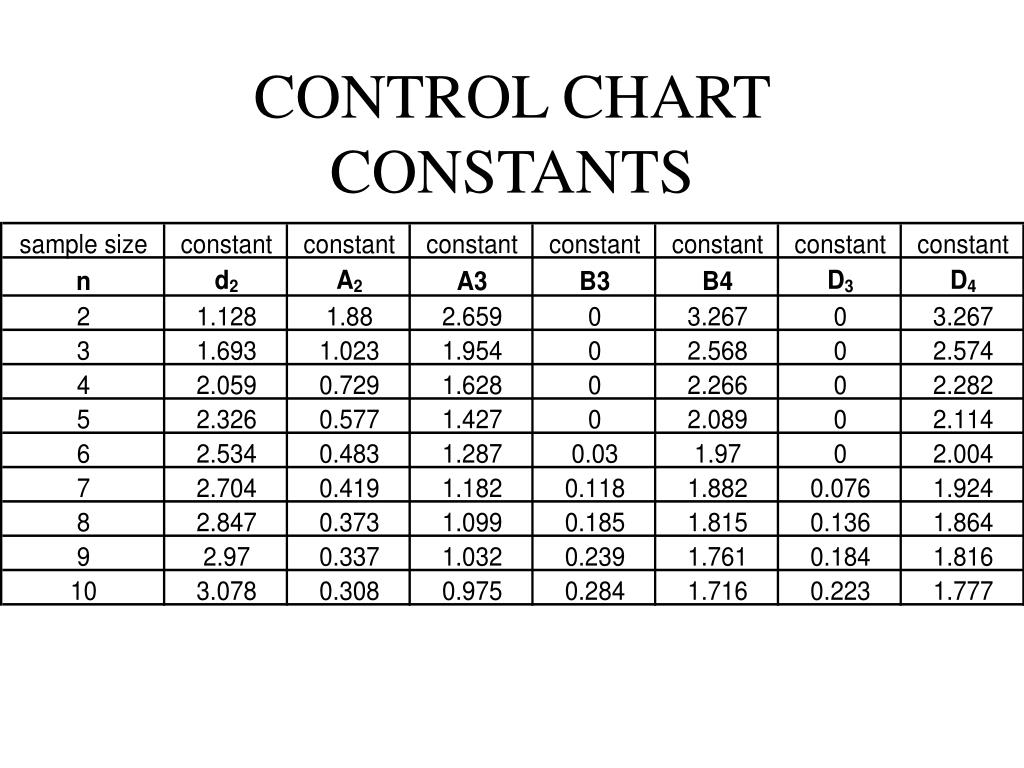

In [223]:
##Se definen las constantes para los subgrupos de n=5
A2 = 0.577
D3 = 0.000
D4 = 2.114
d2 = 2.326

##Usar los datos de la fase 1 para calcular los límites.
fase1 = df_subgrupos[df_subgrupos['fase']== 'Fase I']

#Calcular límites
parametros_fase1 = fase1.groupby(['linea', 'formato_L']).agg(x_doble_barra=('x_mean_sg', 'mean'),R_barra=('rango_sg', 'mean')).reset_index()
display(parametros_fase1)

print('\n'*3, '='*200)


df_limites = parametros_fase1.copy()
##Valores de la carta X
df_limites['LCS_X'] = parametros_fase1['x_doble_barra'] + A2*parametros_fase1['R_barra']
df_limites['LCI_X'] = parametros_fase1['x_doble_barra'] - A2*parametros_fase1['R_barra']
df_limites['LC_X'] = parametros_fase1['x_doble_barra']
##Valores de la carta R
df_limites['LCS_R'] = parametros_fase1['R_barra']*D4
df_limites['LCI_R'] = parametros_fase1['R_barra']*D3
df_limites['LC_R'] = parametros_fase1['R_barra']

display(df_limites)




,linea,formato_L,x_doble_barra,R_barra
0,L1,0.5,502.467417,4.863417
1,L2,1.5,1504.551397,12.010735
2,L2,3.0,3008.888110,19.814451


,linea,formato_L,x_doble_barra,R_barra,LCS_X,LCI_X,LC_X,LCS_R,LCI_R,LC_R
0,L1,0.5,502.467417,4.863417,505.273608,499.661225,502.467417,10.281263,0.0,4.863417
1,L2,1.5,1504.551397,12.010735,1511.481591,1497.621203,1504.551397,25.390694,0.0,12.010735
2,L2,3.0,3008.888110,19.814451,3020.321048,2997.455171,3008.888110,41.887750,0.0,19.814451


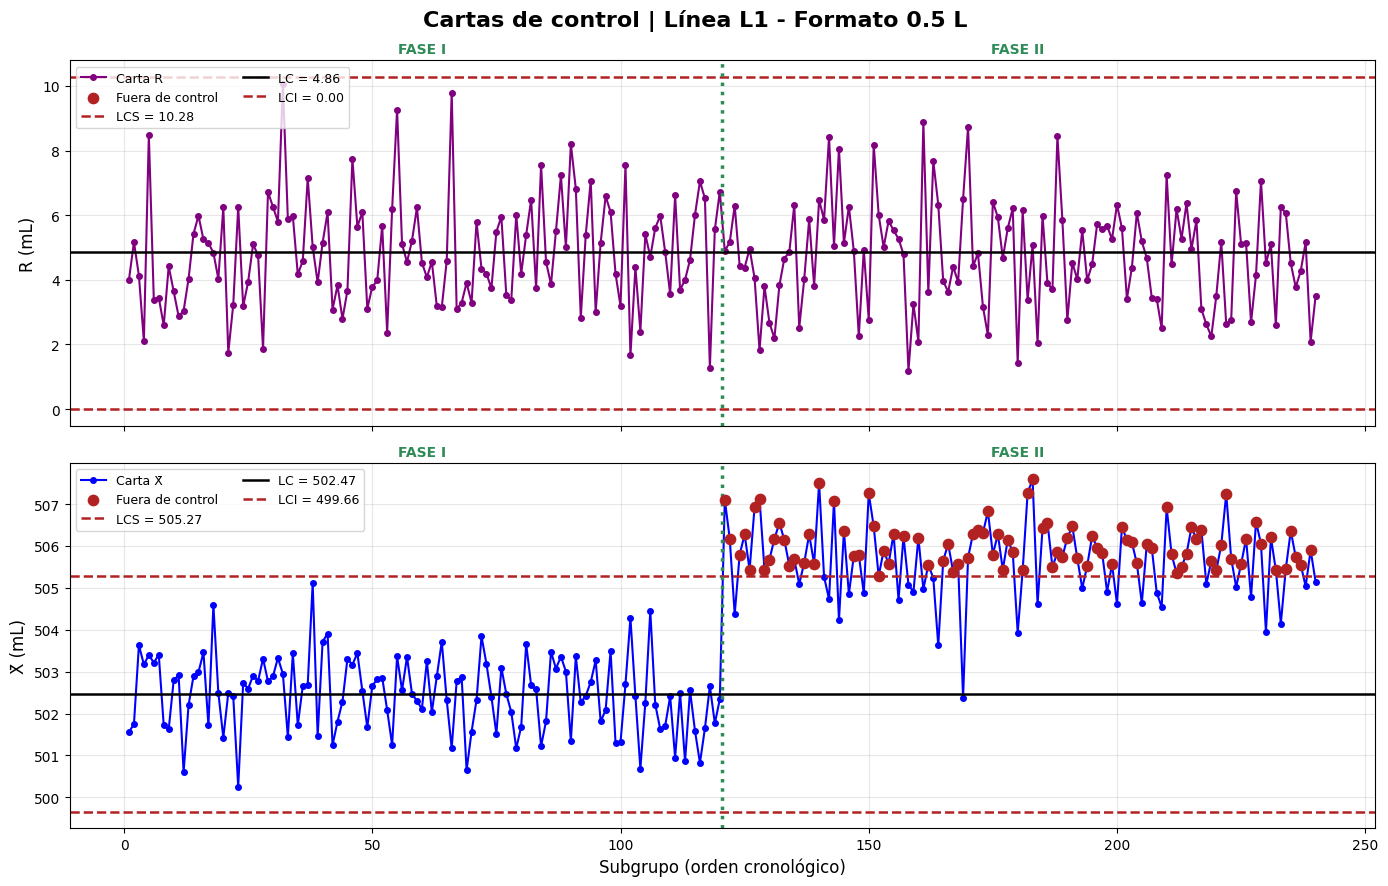

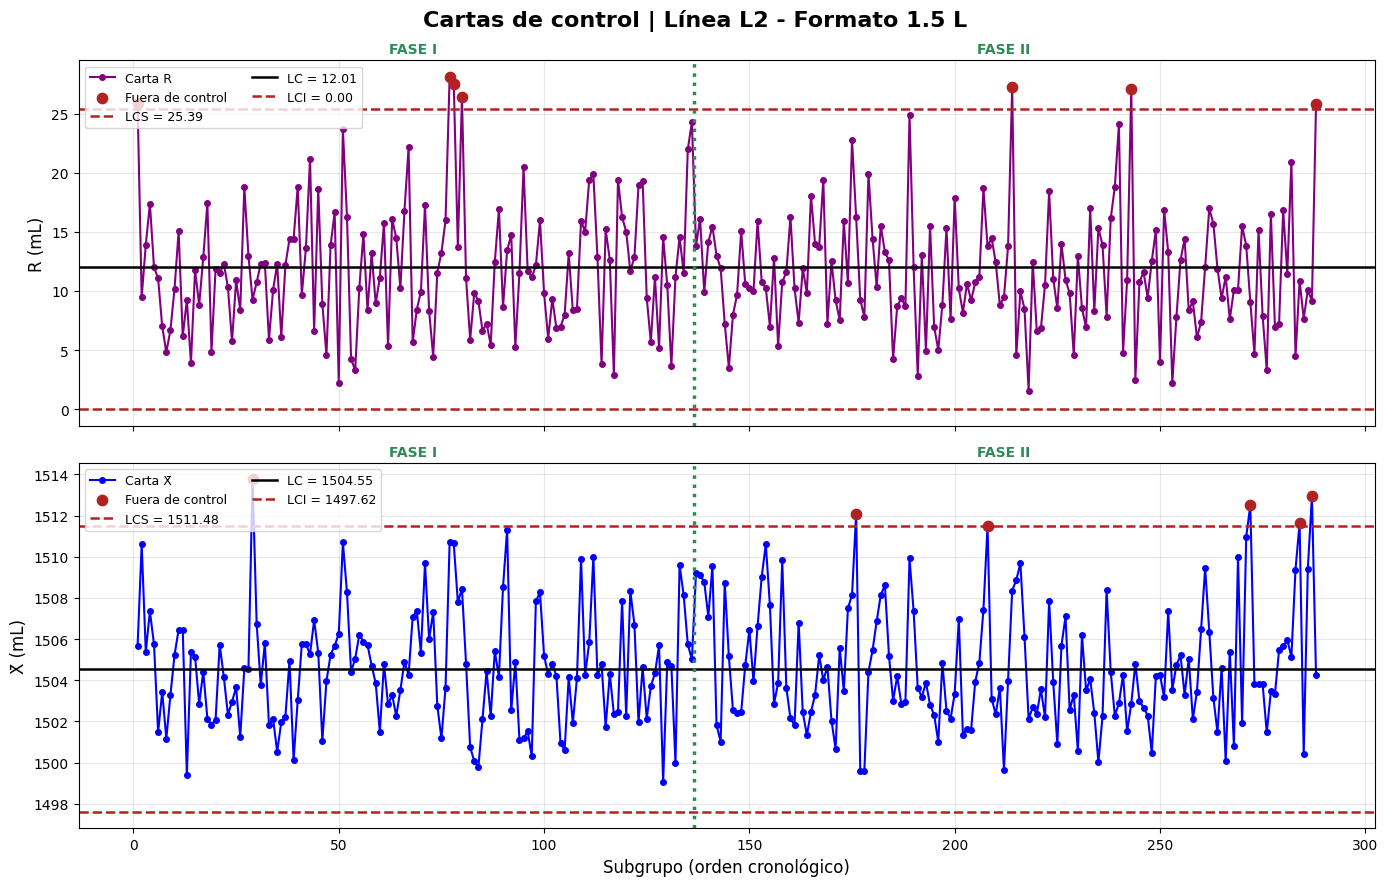

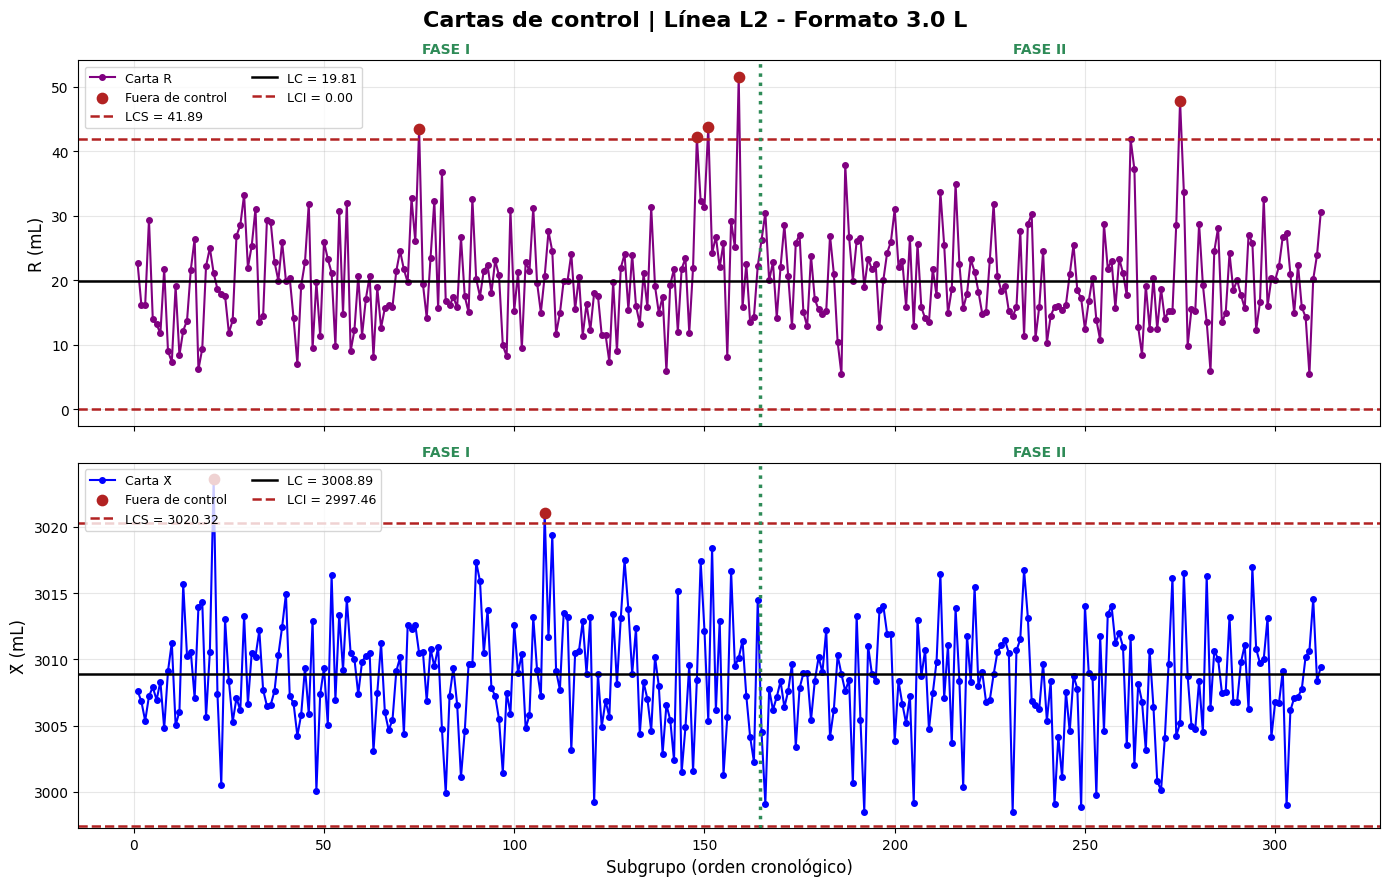

In [224]:
##GRAFICOS
# Ordenar los subgrupos cronológicamente
# Se supone que 'subgrupo' sigue el orden temporal dentro de cada proceso.

for (linea, formato), grupo in df_subgrupos.groupby(['linea', 'formato_L']):

    grupo = grupo.sort_values('subgrupo').copy()
    grupo = grupo.reset_index(drop=True)

    # Posición secuencial en el gráfico
    grupo['posicion'] = np.arange(1, len(grupo) + 1)

    # Obtener límites del proceso
    limites = df_limites[
        (df_limites['linea'] == linea) &
        (df_limites['formato_L'] == formato)
    ].iloc[0]

    # Posición de separación entre fases
    n_fase1 = (grupo['fase'] == 'Fase I').sum()
    separacion = n_fase1 + 0.5

    fig, axes = plt.subplots(
        2, 1,
        figsize=(14, 9),
        sharex=True,
        gridspec_kw={'height_ratios': [1, 1]}
    )

    fig.suptitle(
        f'Cartas de control | Línea {linea} - Formato {formato} L',
        fontsize=16,
        fontweight='bold'
    )

    # Carta R primero, luego carta X
    cartas = [
        ('rango_sg', 'R', 'LC_R', 'LCS_R', 'LCI_R', 'purple'),
        ('x_mean_sg', 'X̄', 'LC_X', 'LCS_X', 'LCI_X', 'blue')
    ]

    for ax, (variable, nombre, lc, lcs, lci, color) in zip(axes, cartas):

        # Detectar puntos fuera de control
        fuera = (
            (grupo[variable] > limites[lcs]) |
            (grupo[variable] < limites[lci])
        )

        # Serie completa
        ax.plot(
            grupo['posicion'],
            grupo[variable],
            color=color,
            marker='o',
            markersize=4,
            linewidth=1.5,
            label=f'Carta {nombre}'
        )

        # Puntos fuera de límites
        ax.scatter(
            grupo.loc[fuera, 'posicion'],
            grupo.loc[fuera, variable],
            color='firebrick',
            s=55,
            zorder=5,
            label='Fuera de control'
        )

        # Límites de control
        ax.axhline(
            limites[lcs],
            color='firebrick',
            linestyle='--',
            linewidth=1.8,
            label=f'LCS = {limites[lcs]:.2f}'
        )

        ax.axhline(
            limites[lc],
            color='black',
            linewidth=1.8,
            label=f'LC = {limites[lc]:.2f}'
        )

        ax.axhline(
            limites[lci],
            color='firebrick',
            linestyle='--',
            linewidth=1.8,
            label=f'LCI = {limites[lci]:.2f}'
        )

        # Separación Fase I / Fase II
        ax.axvline(
            separacion,
            color='seagreen',
            linestyle=':',
            linewidth=2.5
        )

        # Etiquetas de fases
        ax.text(
            n_fase1 / 2,
            1.02,
            'FASE I',
            transform=ax.get_xaxis_transform(),
            ha='center',
            color='seagreen',
            fontweight='bold'
        )

        ax.text(
            (n_fase1 + len(grupo)) / 2,
            1.02,
            'FASE II',
            transform=ax.get_xaxis_transform(),
            ha='center',
            color='seagreen',
            fontweight='bold'
        )

        ax.set_ylabel(f'{nombre} (mL)', fontsize=12)
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper left', fontsize=9, ncol=2)

    axes[1].set_xlabel('Subgrupo (orden cronológico)', fontsize=12)

    plt.tight_layout()
    plt.show()

#DE AQUI PARA ABAJO CHEQUEAR EL METODO

###

In [225]:

# Comparar cada subgrupo de Fase I con sus límites de control
revision = fase1.merge(
    df_limites,
    on=['linea', 'formato_L'],
    how='left'
)

# Detectar subgrupos fuera de control
revision['fuera_X'] = (
    (revision['x_mean_sg'] > revision['LCS_X']) |
    (revision['x_mean_sg'] < revision['LCI_X'])
)

revision['fuera_R'] = (
    (revision['rango_sg'] > revision['LCS_R']) |
    (revision['rango_sg'] < revision['LCI_R'])
)

# Identificar qué límite se superó
revision['senal_X'] = np.select(
    [
        revision['x_mean_sg'] > revision['LCS_X'],
        revision['x_mean_sg'] < revision['LCI_X']
    ],
    ['Sobre LCS', 'Bajo LCI'],
    default='Dentro'
)

revision['senal_R'] = np.select(
    [
        revision['rango_sg'] > revision['LCS_R'],
        revision['rango_sg'] < revision['LCI_R']
    ],
    ['Sobre LCS', 'Bajo LCI'],
    default='Dentro'
)

# Mostrar todos los subgrupos con al menos una señal
fuera_control = revision[
    revision['fuera_X'] | revision['fuera_R']
].copy()

columnas = [
    'linea', 'formato_L', 'subgrupo',
    'semana_registro', 'turno',
    'x_mean_sg', 'LCI_X', 'LCS_X', 'senal_X',
    'rango_sg', 'LCI_R', 'LCS_R', 'senal_R'
]

print(f"Total de subgrupos fuera de control: {len(fuera_control)}")

display(
    fuera_control[columnas]
    .sort_values(['linea', 'formato_L', 'subgrupo'])
)

# Resumen por proceso y carta
print("\nRESUMEN POR PROCESO")

display(
    revision.groupby(['linea', 'formato_L'])
    .agg(
        total_subgrupos=('subgrupo', 'size'),
        fuera_carta_X=('fuera_X', 'sum'),
        fuera_carta_R=('fuera_R', 'sum')
    )
    .reset_index()
)




Total de subgrupos fuera de control: 11


,linea,formato_L,subgrupo,semana_registro,turno,x_mean_sg,LCI_X,LCS_X,senal_X,rango_sg,LCI_R,LCS_R,senal_R
120,L2,1.5,33,1,C (22-06),1505.642,1497.621203,1511.481591,Dentro,25.95,0.0,25.390694,Sobre LCS
148,L2,1.5,129,2,C (22-06),1513.752,1497.621203,1511.481591,Sobre LCS,9.26,0.0,25.390694,Dentro
196,L2,1.5,249,3,C (22-06),1510.722,1497.621203,1511.481591,Dentro,28.13,0.0,25.390694,Sobre LCS
197,L2,1.5,250,3,C (22-06),1510.648,1497.621203,1511.481591,Dentro,27.57,0.0,25.390694,Sobre LCS
199,L2,1.5,252,3,C (22-06),1508.444,1497.621203,1511.481591,Dentro,26.43,0.0,25.390694,Sobre LCS
276,L2,3.0,57,1,C (22-06),3023.588,2997.455171,3020.321048,Sobre LCS,21.08,0.0,41.887750,Dentro
330,L2,3.0,203,3,C (22-06),3010.470,2997.455171,3020.321048,Dentro,43.43,0.0,41.887750,Sobre LCS
363,L2,3.0,300,4,C (22-06),3021.058,2997.455171,3020.321048,Sobre LCS,20.58,0.0,41.887750,Dentro
403,L2,3.0,392,5,B (14-22),3008.436,2997.455171,3020.321048,Dentro,42.19,0.0,41.887750,Sobre LCS
406,L2,3.0,395,5,C (22-06),3005.366,2997.455171,3020.321048,Dentro,43.67,0.0,41.887750,Sobre LCS



RESUMEN POR PROCESO


,linea,formato_L,total_subgrupos,fuera_carta_X,fuera_carta_R
0,L1,0.5,120,0,0
1,L2,1.5,136,1,4
2,L2,3.0,164,2,4


In [205]:

# Evaluar TODOS los subgrupos (Fase I y Fase II)
revision = df_subgrupos.merge(
    df_limites,
    on=['linea', 'formato_L'],
    how='left',
    validate='many_to_one'
)

# Identificar qué límite viola cada subgrupo
revision['violacion_X'] = np.select(
    [
        revision['x_mean_sg'] > revision['LCS_X'],
        revision['x_mean_sg'] < revision['LCI_X']
    ],
    ['LCS_X', 'LCI_X'],
    default=''
)

revision['violacion_R'] = np.select(
    [
        revision['rango_sg'] > revision['LCS_R'],
        revision['rango_sg'] < revision['LCI_R']
    ],
    ['LCS_R', 'LCI_R'],
    default=''
)

# Crear DataFrame solo con subgrupos fuera de control
subgrupos_fuera_control = revision.loc[
    (revision['violacion_X'] != '') |
    (revision['violacion_R'] != '')
].copy()

# Indicar todos los límites violados
subgrupos_fuera_control['limites_violados'] = (
    subgrupos_fuera_control[['violacion_X', 'violacion_R']]
    .agg(lambda fila: ', '.join(v for v in fila if v), axis=1)
)

# Seleccionar columnas
subgrupos_fuera_control = subgrupos_fuera_control[
    [
        'linea', 'formato_L', 'subgrupo',
        'semana_registro', 'fase', 'turno',
        'x_mean_sg', 'rango_sg', 'limites_violados'
    ]
].sort_values(
    ['linea', 'formato_L', 'semana_registro', 'subgrupo']
).reset_index(drop=True)

print("TODOS LOS SUBGRUPOS FUERA DE CONTROL")
display(subgrupos_fuera_control)

print("\nRESUMEN POR PROCESO Y FASE")
display(
    subgrupos_fuera_control.groupby(
        ['linea', 'formato_L', 'fase']
    ).size().reset_index(name='cantidad_fuera_control')
)


TODOS LOS SUBGRUPOS FUERA DE CONTROL


,linea,formato_L,subgrupo,semana_registro,fase,turno,x_mean_sg,rango_sg,limites_violados
0,L1,0.5,92,2,Fase I,B (14-22),502.946,10.06,LCS_R
1,L1,0.5,421,6,Fase II,A (06-14),507.106,4.90,LCS_X
2,L1,0.5,422,6,Fase II,A (06-14),506.174,5.16,LCS_X
3,L1,0.5,424,6,Fase II,A (06-14),505.794,4.43,LCS_X
4,L1,0.5,425,6,Fase II,B (14-22),506.274,4.38,LCS_X
...,...,...,...,...,...,...,...,...,...
107,L2,3.0,392,5,Fase I,B (14-22),3008.436,42.19,LCS_R
108,L2,3.0,395,5,Fase I,C (22-06),3005.366,43.67,LCS_R
109,L2,3.0,407,5,Fase I,C (22-06),3010.112,51.49,LCS_R
110,L2,3.0,666,8,Fase II,B (14-22),3011.728,41.86,LCS_R



RESUMEN POR PROCESO Y FASE


,linea,formato_L,fase,cantidad_fuera_control
0,L1,0.5,Fase I,1
1,L1,0.5,Fase II,88
2,L2,1.5,Fase I,6
3,L2,1.5,Fase II,9
4,L2,3.0,Fase I,6
5,L2,3.0,Fase II,2


In [235]:

# Incorporar límites de control
df_nelson = df_subgrupos.merge(
    df_limites,
    on=['linea', 'formato_L'],
    how='left'
)

# Función 1: Reglas de Nelson para carta X
def nelson_X(grupo):
    grupo = grupo.sort_values('subgrupo').copy()
    x = grupo['x_mean_sg']

    # Regla 1: Fuera de 3 sigma
    grupo['X_N1'] = (
        (x > grupo['LCS_X']) |
        (x < grupo['LCI_X'])
    )

    # Regla 2: 9 puntos del mismo lado
    arriba = x > grupo['LC_X']
    abajo = x < grupo['LC_X']

    grupo['X_N2'] = (
        arriba.rolling(9).sum().eq(9) |
        abajo.rolling(9).sum().eq(9)
    )

    # Regla 3: 6 puntos en tendencia
    diferencias = x.diff()

    grupo['X_N3'] = (
        diferencias.gt(0).rolling(5).sum().eq(5) |
        diferencias.lt(0).rolling(5).sum().eq(5)
    )

    return grupo


# Función 2: Reglas de Nelson para carta R
def nelson_R(grupo):
    grupo = grupo.sort_values('subgrupo').copy()
    r = grupo['rango_sg']

    # Regla 1: Fuera de límites
    grupo['R_N1'] = (
        (r > grupo['LCS_R']) |
        (r < grupo['LCI_R'])
    )

    # Regla 2: 9 puntos del mismo lado
    arriba = r > grupo['LC_R']
    abajo = r < grupo['LC_R']

    grupo['R_N2'] = (
        arriba.rolling(9).sum().eq(9) |
        abajo.rolling(9).sum().eq(9)
    )

    # Regla 3: 6 puntos en tendencia
    diferencias = r.diff()

    grupo['R_N3'] = (
        diferencias.gt(0).rolling(5).sum().eq(5) |
        diferencias.lt(0).rolling(5).sum().eq(5)
    )

    return grupo


# Aplicar por proceso
resultados = []

for _, grupo in df_nelson.groupby(
    ['linea', 'formato_L']
):
    grupo = nelson_X(grupo)
    grupo = nelson_R(grupo)
    resultados.append(grupo)

df_nelson = pd.concat(resultados, ignore_index=True)

# Resumen por fase
columnas = [
    'X_N1', 'X_N2', 'X_N3',
    'R_N1', 'R_N2', 'R_N3'
]

resumen = (
    df_nelson
    .groupby(['linea', 'formato_L', 'fase'])[columnas]
    .sum()
    .reset_index()
)

display(resumen)

print('existe evidencia de un cambio importante en el nivel promedio de llenado, mientras la variabilidad dentro de los subgrupos parece mantenerse relativamente estable. \n\n')

print('el proceso presenta evidencia de inestabilidad tanto en su nivel promedio como en su dispersión.')
print('Además, las cuatro señales R_N1 de Fase I indican que los límites iniciales de la carta R necesitan investigación antes de considerarse definitivos. \n\n')


print('En Fase I existen señales de inestabilidad en ambas cartas.', '\n',' En Fase II desaparecen los puntos fuera de los límites de la carta X̄, pero persisten señales de patrones no aleatorios. \nInterpretación: aunque las medias se mantienen dentro de los límites de 3σ en Fase II, no podemos concluir que el proceso sea estable.')

,linea,formato_L,fase,X_N1,X_N2,X_N3,R_N1,R_N2,R_N3
0,L1,0.5,Fase I,0,1,0,0,0,0
1,L1,0.5,Fase II,91,103,0,0,0,1
2,L2,1.5,Fase I,1,0,2,4,0,0
3,L2,1.5,Fase II,5,1,2,3,0,0
4,L2,3.0,Fase I,2,0,1,4,3,1
5,L2,3.0,Fase II,0,2,4,1,0,0


existe evidencia de un cambio importante en el nivel promedio de llenado, mientras la variabilidad dentro de los subgrupos parece mantenerse relativamente estable. 


el proceso presenta evidencia de inestabilidad tanto en su nivel promedio como en su dispersión.
Además, las cuatro señales R_N1 de Fase I indican que los límites iniciales de la carta R necesitan investigación antes de considerarse definitivos. 


En Fase I existen señales de inestabilidad en ambas cartas. 
  En Fase II desaparecen los puntos fuera de los límites de la carta X̄, pero persisten señales de patrones no aleatorios. 
Interpretación: aunque las medias se mantienen dentro de los límites de 3σ en Fase II, no podemos concluir que el proceso sea estable.


In [238]:

# Incorporar límites de control
df_nelson = df_subgrupos.merge(
    df_limites,
    on=['linea', 'formato_L'],
    how='left'
)

# Función 1: Reglas de Nelson para carta X
def nelson_X(grupo):
    grupo = grupo.sort_values(
        ['semana_registro', 'subgrupo']
    ).copy()

    x = grupo['x_mean_sg']

    # Regla 1: Fuera de 3 sigma
    grupo['X_N1'] = (
        (x > grupo['LCS_X']) |
        (x < grupo['LCI_X'])
    )

    # Regla 2: 9 puntos del mismo lado
    arriba = x > grupo['LC_X']
    abajo = x < grupo['LC_X']

    grupo['X_N2'] = (
        arriba.rolling(9).sum().eq(9) |
        abajo.rolling(9).sum().eq(9)
    )

    # Regla 3: 6 puntos en tendencia
    diferencias = x.diff()

    grupo['X_N3'] = (
        diferencias.gt(0).rolling(5).sum().eq(5) |
        diferencias.lt(0).rolling(5).sum().eq(5)
    )

    return grupo


# Función 2: Reglas de Nelson para carta R
def nelson_R(grupo):
    grupo = grupo.sort_values(
        ['semana_registro', 'subgrupo']
    ).copy()

    r = grupo['rango_sg']

    # Regla 1: Fuera de límites
    grupo['R_N1'] = (
        (r > grupo['LCS_R']) |
        (r < grupo['LCI_R'])
    )

    # Regla 2: 9 puntos del mismo lado
    arriba = r > grupo['LC_R']
    abajo = r < grupo['LC_R']

    grupo['R_N2'] = (
        arriba.rolling(9).sum().eq(9) |
        abajo.rolling(9).sum().eq(9)
    )

    # Regla 3: 6 puntos en tendencia
    diferencias = r.diff()

    grupo['R_N3'] = (
        diferencias.gt(0).rolling(5).sum().eq(5) |
        diferencias.lt(0).rolling(5).sum().eq(5)
    )

    return grupo


    # Aplicar por proceso
resultados = []

for _, grupo in df_nelson.groupby(
    ['linea', 'formato_L']
):
    grupo = nelson_X(grupo)
    grupo = nelson_R(grupo)
    resultados.append(grupo)

df_nelson = pd.concat(resultados, ignore_index=True)

# Resumen por fase
columnas = [
    'X_N1', 'X_N2', 'X_N3',
    'R_N1', 'R_N2', 'R_N3'
]

resumen = (
    df_nelson
    .groupby(['linea', 'formato_L', 'fase'])[columnas]
    .sum()
    .reset_index()
)

display(resumen)

print('existe evidencia de un cambio importante en el nivel promedio de llenado, mientras la variabilidad dentro de los subgrupos parece mantenerse relativamente estable. \n\n')

print('el proceso presenta evidencia de inestabilidad tanto en su nivel promedio como en su dispersión.')
print('Además, las cuatro señales R_N1 de Fase I indican que los límites iniciales de la carta R necesitan investigación antes de considerarse definitivos. \n\n')


print('En Fase I existen señales de inestabilidad en ambas cartas.', '\n',' En Fase II desaparecen los puntos fuera de los límites de la carta X̄, pero persisten señales de patrones no aleatorios. \nInterpretación: aunque las medias se mantienen dentro de los límites de 3σ en Fase II, no podemos concluir que el proceso sea estable.')

,linea,formato_L,fase,X_N1,X_N2,X_N3,R_N1,R_N2,R_N3
0,L1,0.5,Fase I,0,1,0,0,0,0
1,L1,0.5,Fase II,91,103,0,0,0,1
2,L2,1.5,Fase I,1,0,2,4,0,0
3,L2,1.5,Fase II,5,1,2,3,0,0
4,L2,3.0,Fase I,2,0,1,4,3,1
5,L2,3.0,Fase II,0,2,4,1,0,0


existe evidencia de un cambio importante en el nivel promedio de llenado, mientras la variabilidad dentro de los subgrupos parece mantenerse relativamente estable. 


el proceso presenta evidencia de inestabilidad tanto en su nivel promedio como en su dispersión.
Además, las cuatro señales R_N1 de Fase I indican que los límites iniciales de la carta R necesitan investigación antes de considerarse definitivos. 


En Fase I existen señales de inestabilidad en ambas cartas. 
  En Fase II desaparecen los puntos fuera de los límites de la carta X̄, pero persisten señales de patrones no aleatorios. 
Interpretación: aunque las medias se mantienen dentro de los límites de 3σ en Fase II, no podemos concluir que el proceso sea estable.


In [239]:
display(
    calidad_llenado[
        ['linea', 'formato_L', 'semana_registro',
         'subgrupo', 'fecha', 'hora', 'turno']
    ].drop_duplicates().sort_values(
        ['linea', 'formato_L', 'semana_registro', 'subgrupo']
    ).head(30)
)

,linea,formato_L,semana_registro,subgrupo,fecha,hora,turno
0,L1,0.5,1,1,2026-07-20,06:00,A (06-14)
10,L1,0.5,1,2,2026-07-20,08:00,A (06-14)
20,L1,0.5,1,3,2026-07-20,10:00,A (06-14)
30,L1,0.5,1,4,2026-07-20,12:00,A (06-14)
40,L1,0.5,1,5,2026-07-20,14:00,B (14-22)
50,L1,0.5,1,6,2026-07-20,16:00,B (14-22)
60,L1,0.5,1,7,2026-07-20,18:00,B (14-22)
70,L1,0.5,1,8,2026-07-20,20:00,B (14-22)
100,L1,0.5,1,9,2026-07-21,06:00,A (06-14)
110,L1,0.5,1,10,2026-07-21,08:00,A (06-14)


In [240]:
for (linea, formato), grupo in calidad_llenado.groupby(
    ['linea', 'formato_L']
):
    grupo = grupo.sort_values(
        ['semana_registro', 'subgrupo', 'n_obs']
    )

    print(
        linea, formato,
        "Orden cronológico:",
        grupo['fecha_hora'].is_monotonic_increasing
    )

L1 0.5 Orden cronológico: True
L2 1.5 Orden cronológico: True
L2 3.0 Orden cronológico: True


In [241]:

# Seleccionar únicamente Fase I
fase1_nelson = df_nelson[
    df_nelson['fase'] == 'Fase I'
].copy()

# Identificar subgrupos fuera de los límites de control
senales_fase1 = fase1_nelson[
    fase1_nelson['X_N1'] | fase1_nelson['R_N1']
].copy()

# Identificar qué carta generó la señal
senales_fase1['tipo_senal'] = np.select(
    [
        senales_fase1['X_N1'] & senales_fase1['R_N1'],
        senales_fase1['X_N1'],
        senales_fase1['R_N1']
    ],
    ['Ambas', 'Media X', 'Rango R'],
    default='Sin señal'
)

# Mostrar resultados
display(
    senales_fase1[
        ['linea', 'formato_L', 'subgrupo',
         'semana_registro', 'turno',
         'x_mean_sg', 'rango_sg',
         'tipo_senal']
    ].sort_values(
        ['linea', 'formato_L',
         'semana_registro', 'subgrupo']
    )
)


,linea,formato_L,subgrupo,semana_registro,turno,x_mean_sg,rango_sg,tipo_senal
240,L2,1.5,33,1,C (22-06),1505.642,25.95,Rango R
268,L2,1.5,129,2,C (22-06),1513.752,9.26,Media X
316,L2,1.5,249,3,C (22-06),1510.722,28.13,Rango R
317,L2,1.5,250,3,C (22-06),1510.648,27.57,Rango R
319,L2,1.5,252,3,C (22-06),1508.444,26.43,Rango R
548,L2,3.0,57,1,C (22-06),3023.588,21.08,Media X
602,L2,3.0,203,3,C (22-06),3010.470,43.43,Rango R
635,L2,3.0,300,4,C (22-06),3021.058,20.58,Media X
675,L2,3.0,392,5,B (14-22),3008.436,42.19,Rango R
678,L2,3.0,395,5,C (22-06),3005.366,43.67,Rango R


In [242]:

# Recuperar registros originales de los subgrupos señalados
detalle_senales = calidad_llenado.merge(
    senales_fase1[
        ['linea', 'formato_L', 'subgrupo',
         'semana_registro', 'turno', 'tipo_senal']
    ],
    on=['linea', 'formato_L', 'subgrupo',
        'semana_registro', 'turno'],
    how='inner',
    validate='many_to_one'
)

# Resumen de condiciones operacionales
resumen_causas = (
    detalle_senales
    .groupby(
        ['linea', 'formato_L', 'subgrupo',
         'semana_registro', 'turno', 'sku',
         'tipo_senal'],
        dropna=False
    )
    .agg(
        fecha=('fecha', 'min'),
        volumen_min=('volumen_mL', 'min'),
        volumen_max=('volumen_mL', 'max'),
        volumen_promedio=('volumen_mL', 'mean'),
        n_mediciones=('volumen_mL', 'size')
    )
    .reset_index()
)

display(resumen_causas)


,linea,formato_L,subgrupo,semana_registro,turno,sku,tipo_senal,fecha,volumen_min,volumen_max,volumen_promedio,n_mediciones
0,L2,1.5,33,1,C (22-06),NEC-D15,Rango R,2026-07-20,1493.73,1519.68,1505.642,5
1,L2,1.5,129,2,C (22-06),NEC-D15,Media X,2026-07-28,1507.29,1516.55,1513.752,5
2,L2,1.5,249,3,C (22-06),FUN-B15,Rango R,2026-08-07,1497.06,1525.19,1510.722,5
3,L2,1.5,250,3,C (22-06),FUN-B15,Rango R,2026-08-07,1494.00,1521.57,1510.648,5
4,L2,1.5,252,3,C (22-06),FUN-B15,Rango R,2026-08-07,1494.40,1520.83,1508.444,5
5,L2,3.0,57,1,C (22-06),FUN-B30,Media X,2026-07-22,3014.77,3035.85,3023.588,5
6,L2,3.0,203,3,C (22-06),FUN-B30,Rango R,2026-08-03,2989.73,3033.16,3010.470,5
7,L2,3.0,300,4,C (22-06),FUN-B30,Media X,2026-08-11,3009.91,3030.49,3021.058,5
8,L2,3.0,392,5,B (14-22),CIT-L30,Rango R,2026-08-19,2986.10,3028.29,3008.436,5
9,L2,3.0,395,5,C (22-06),NEC-D30,Rango R,2026-08-19,2983.53,3027.20,3005.366,5


In [243]:

# Tasa de señales de la regla 1 por turno y proceso
fase1_nelson = df_nelson[
    df_nelson['fase'] == 'Fase I'
].copy()

fase1_nelson['senal_N1'] = (
    fase1_nelson['X_N1'] | fase1_nelson['R_N1']
)

resumen_turnos = (
    fase1_nelson
    .groupby(['linea', 'formato_L', 'turno'])
    .agg(
        total_subgrupos=('subgrupo', 'size'),
        subgrupos_senalados=('senal_N1', 'sum')
    )
    .reset_index()
)

resumen_turnos['porcentaje_senales'] = (
    100 * resumen_turnos['subgrupos_senalados']
    / resumen_turnos['total_subgrupos']
)

display(resumen_turnos)


,linea,formato_L,turno,total_subgrupos,subgrupos_senalados,porcentaje_senales
0,L1,0.5,A (06-14),60,0,0.000000
1,L1,0.5,B (14-22),60,0,0.000000
2,L2,1.5,A (06-14),64,0,0.000000
3,L2,1.5,B (14-22),24,0,0.000000
4,L2,1.5,C (22-06),48,5,10.416667
5,L2,3.0,A (06-14),36,0,0.000000
6,L2,3.0,B (14-22),76,1,1.315789
7,L2,3.0,C (22-06),52,5,9.615385
